In [1]:
import pandas as pd 
import numpy as np 
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

In [2]:
df = pd.read_csv("train.csv")

In [3]:
df.Pclass.value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [4]:
df.Embarked.value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [5]:
df.head(50)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Exploratory Data Analysis

Before engineering more features, check missingness and look at how survival relates to the raw columns. This is what tells you which engineered features are actually worth building, instead of guessing.

In [7]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

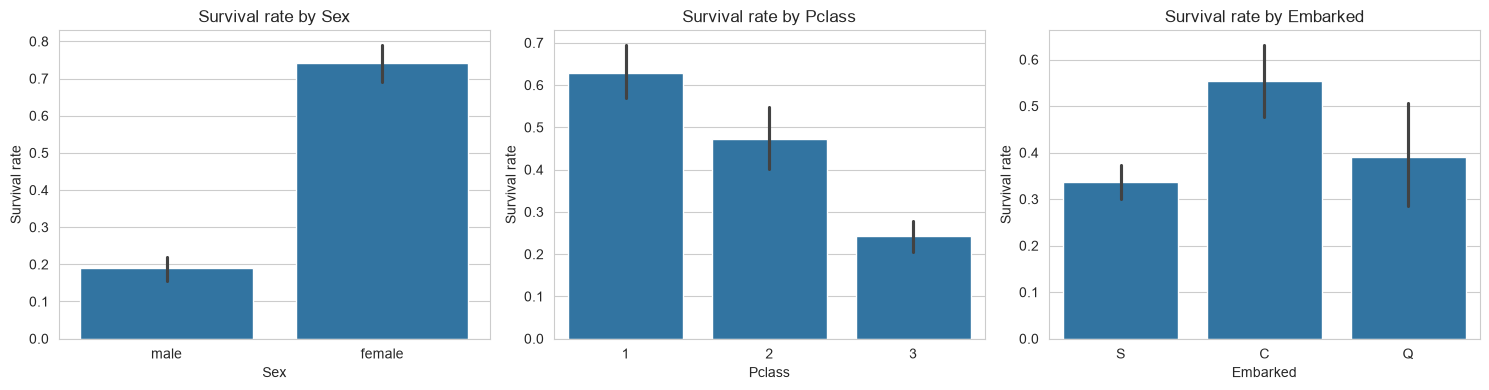

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(data=df, x=col, y="Survived", ax=ax)
    ax.set_title(f"Survival rate by {col}")
    ax.set_ylabel("Survival rate")

plt.tight_layout()
plt.show()

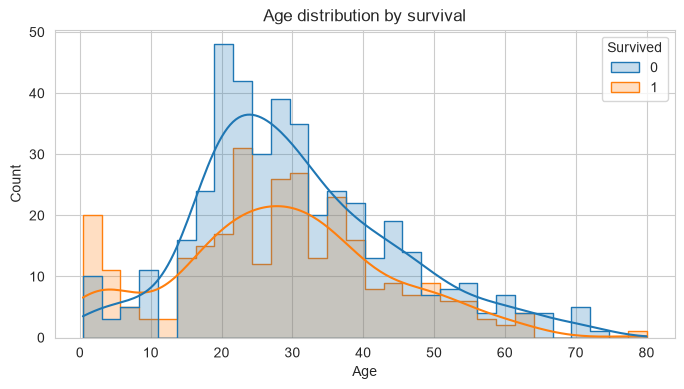

In [10]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="Age", hue="Survived", kde=True, element="step", bins=30)
plt.title("Age distribution by survival")
plt.show()

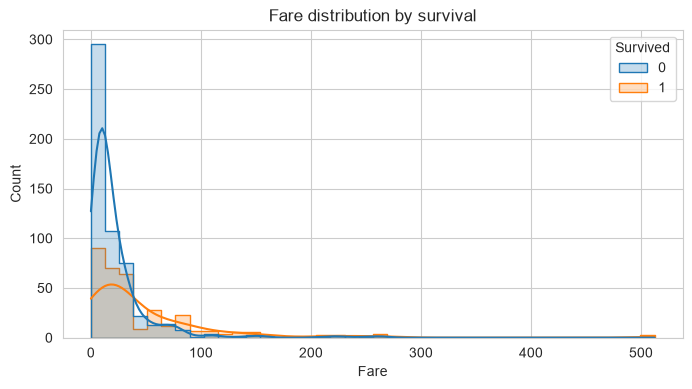

In [11]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="Fare", hue="Survived", kde=True, element="step", bins=40)
plt.title("Fare distribution by survival")
plt.show()

**Questions to think about from these plots:**
- Which of `Sex`, `Pclass`, `Embarked` looks most predictive on its own? Does that match what you'd expect from feature importance later?
- Is `Embarked` worth keeping as a feature, or is it mostly a proxy for something else (hint: check how `Embarked` relates to `Pclass`/`Fare`)?
- Does the `Age` distribution suggest a good imputation strategy beyond a single global median (e.g. per `Pclass`/`Title` group)?
- `Fare` is heavily skewed — would a log transform make the survived/died groups easier to separate?

In [12]:
df["Title"] = (
    df["Name"]
    .str.extract(r",\s*([^.]*)\.")[0]
    .str.strip()
)

df["Title"] = df["Title"].replace(
    ["Lady", "the Countess", "Capt", "Col", "Don", "Dr",
     "Major", "Rev", "Sir", "Jonkheer", "Dona"],
    "Rare"
)

df["Title"] = df["Title"].replace({
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs"
})

In [13]:
df["Title"].value_counts()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

In [14]:
X = df.drop("Survived", axis=1)
y = df["Survived"]

X = pd.get_dummies(X, columns=["Title"], dtype=int)

In [15]:
X.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0,0,1,0,0
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,0,0,0,1,0
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,1,0,0,0
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,0,0,0,1,0
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0,0,1,0,0


In [16]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [17]:
print(X_train.shape, X_val.shape)
print(y_train.mean(), y_val.mean())

(712, 16) (179, 16)
0.38342696629213485 0.3854748603351955


In [18]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 712 entries, 692 to 507
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   712 non-null    int64  
 1   Pclass        712 non-null    int64  
 2   Name          712 non-null    str    
 3   Sex           712 non-null    str    
 4   Age           575 non-null    float64
 5   SibSp         712 non-null    int64  
 6   Parch         712 non-null    int64  
 7   Ticket        712 non-null    str    
 8   Fare          712 non-null    float64
 9   Cabin         160 non-null    str    
 10  Embarked      710 non-null    str    
 11  Title_Master  712 non-null    int64  
 12  Title_Miss    712 non-null    int64  
 13  Title_Mr      712 non-null    int64  
 14  Title_Mrs     712 non-null    int64  
 15  Title_Rare    712 non-null    int64  
dtypes: float64(2), int64(9), str(5)
memory usage: 122.9 KB


In [19]:
X_train["Sex"] = X_train["Sex"].map({"male": 0, "female": 1})

In [20]:
X_train = X_train.drop(["Cabin", "Embarked", "Name", "Ticket", "PassengerId"], axis=1)

In [21]:
X_val["Sex"] = X_val["Sex"].map({"male": 0, "female": 1})
X_val = X_val.drop(
    ["Cabin", "Embarked", "Name", "Ticket", "PassengerId"], axis=1
)

In [22]:
title_age_medians = X_train.groupby("Title")["Age"].median()

X_train["Age"] = X_train["Age"].fillna(X_train["Title"].map(title_age_medians))
X_val["Age"] = X_val["Age"].fillna(X_val["Title"].map(title_age_medians))

KeyError: 'Title'

In [ ]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 712 entries, 692 to 507
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Pclass        712 non-null    int64  
 1   Sex           712 non-null    int64  
 2   Age           712 non-null    float64
 3   SibSp         712 non-null    int64  
 4   Parch         712 non-null    int64  
 5   Fare          712 non-null    float64
 6   Title_Master  712 non-null    int64  
 7   Title_Miss    712 non-null    int64  
 8   Title_Mr      712 non-null    int64  
 9   Title_Mrs     712 non-null    int64  
 10  Title_Rare    712 non-null    int64  
dtypes: float64(2), int64(9)
memory usage: 66.8 KB


In [ ]:
X_train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
692,3,0,28.5,0,0,56.4958,0,0,1,0,0
481,2,0,28.5,0,0,0.0000,0,0,1,0,0
527,1,0,28.5,0,0,221.7792,0,0,1,0,0
855,3,1,18.0,0,1,9.3500,0,0,0,1,0
801,2,1,31.0,1,1,26.2500,0,0,0,1,0


In [ ]:
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

val_predictions = model.predict(X_val)

val_accuracy = accuracy_score(y_val, val_predictions)

print("Validation accuracy: ", val_accuracy)

Validation accuracy:  0.8379888268156425


In [ ]:
train_accuracy = model.score(X_train, y_train)

print("Training accuracy:", train_accuracy)
print("Validation accuracy:", val_accuracy)
print(classification_report(y_val, model.predict(X_val)))

Training accuracy: 0.8370786516853933
Validation accuracy: 0.8379888268156425
              precision    recall  f1-score   support

           0       0.85      0.89      0.87       110
           1       0.81      0.75      0.78        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



In [ ]:
feature_importance = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

feature_importance

Title_Mr        0.628059
Fare            0.155574
Pclass          0.155052
Title_Rare      0.061315
Sex             0.000000
Age             0.000000
SibSp           0.000000
Parch           0.000000
Title_Master    0.000000
Title_Miss      0.000000
Title_Mrs       0.000000
dtype: float64

In [ ]:
scores = cross_val_score(
    DecisionTreeClassifier(max_depth=3, random_state=42),
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print(scores)
print("Mean CV accuracy:", scores.mean())

[0.8041958  0.74825175 0.80985915 0.83802817 0.85915493]
Mean CV accuracy: 0.8118979611937359


In [ ]:
pd.crosstab(df["Embarked"], df["Pclass"], normalize="index")

Pclass,1,2,3
Embarked,,,
C,0.505952,0.101190,0.392857
Q,0.025974,0.038961,0.935065
S,0.197205,0.254658,0.548137
